# RetailHero · A/B-анализ и uplift-моделирование

**X5 RetailHero | Python · A/B Testing · Machine Learning**

**Бизнес-задача:** оценить эффект исторической маркетинговой коммуникации и выяснить, можно ли повысить число дополнительных покупок при фиксированном числе SMS, выбирая аудиторию по uplift-score.

Автор анализирует **уже проведённый** эксперимент. Рандомизация исходной кампании и отправка сообщений не выполнялись автором проекта. Предложение следующего A/B-теста маркетинговых стратегий изложено в [дизайне эксперимента](../docs/next_ab_experiment.md).

| Результат опубликованного запуска | Значение |
|:--|--:|
| Клиентов в исходном A/B-эксперименте | **200 039** |
| Конверсия: контроль / коммуникация | **60,33% / 63,65%** |
| Средний эффект | **+3,32 п. п.** |
| Наблюдаемый uplift топ-10% по модели (holdout; только демография) | **+4,922 п. п.** |
| Относительное преимущество базовой модели на контакт | **+1,591 п. п.**, 95% ДИ **[−0,756; +3,898]** |
| RFM-модель с историей покупок: uplift топ-10% (Colab, 30.10.2026) | **≈+6,80 п. п.** |
| Преимущество RFM-модели на контакт (точечная оценка) | **+3,483 п. п.**, 95% bootstrap ДИ **[+1,129; +5,922]** |

**Важное ограничение:** сохранённый запуск сделан без необязательного файла истории покупок `final_stats.csv`; результаты с расширенными признаками могут отличаться. Цифры выше воспроизводятся **только для показанного запуска**. Это оценка на историческом holdout, а не результат нового A/B-теста стратегий.
> **Архив выполненного RFM-анализа, 30.10.2026:** в этом файле `BUILD_RFM = True`; выводы, таблицы и графики сохранены. [Базовый ноутбук](RetailHero_AB_Uplift.ipynb) не требует загрузки истории покупок.


## 1. Данные

Используются два файла RetailHero: участники эксперимента с признаком коммуникации (`treatment_flg`) и фактом покупки (`target`), а также данные о клиентах. История покупок подключается отдельно в виде агрегатов на клиента.

In [16]:
%pip -q install huggingface_hub pandas numpy scipy statsmodels scikit-learn matplotlib

In [17]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chisquare
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.multitest import multipletests
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
import statsmodels.formula.api as smf
from huggingface_hub import hf_hub_download

pd.set_option('display.float_format', '{:.3f}'.format)
plt.rcParams.update({
    'figure.figsize': (9, 4), 'figure.dpi': 125,
    'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False
})
GREEN, GRAY = '#147d74', '#9aa9b5'

DATA_DIR = Path('data')
DATA_DIR.mkdir(exist_ok=True)
REPO = 'pytorch-lifestream/retailhero-uplift'


def load_file(name):
    local = DATA_DIR / name
    if not local.exists():
        local = Path(hf_hub_download(
            repo_id=REPO, filename=f'data/{name}', repo_type='dataset'
        ))
    return pd.read_csv(local, dtype={'client_id': 'string'})

ab = load_file('uplift_train.csv.gz')
clients = load_file('clients.csv.gz')

data = ab.merge(clients, on='client_id', how='left', validate='one_to_one')
assert data['client_id'].is_unique
assert data['treatment_flg'].isin([0, 1]).all()
assert data['target'].isin([0, 1]).all()

print('Клиентов:', len(data))
display(data[['treatment_flg', 'target', 'age', 'gender']].head())

Клиентов: 200039


,treatment_flg,target,age,gender
0,0,1,45,U
1,1,1,72,F
2,1,1,83,U
3,1,1,33,F
4,1,1,73,U


## 2. A/B-тест

**H₀:** коммуникация не влияет на конверсию.  
**H₁:** конверсия между группами различается.

Основная метрика — доля клиентов с `target = 1`. Для сравнения используем z-тест двух долей и 95% доверительный интервал разности.

In [18]:
summary = data.groupby('treatment_flg')['target'].agg(['size', 'sum', 'mean'])
summary.columns = ['clients', 'buyers', 'conversion']

n0, n1 = summary['clients'].to_numpy()
b0, b1 = summary['buyers'].to_numpy()
p0, p1 = summary['conversion'].to_numpy()

effect = p1 - p0
se = np.sqrt(p0 * (1 - p0) / n0 + p1 * (1 - p1) / n1)
ci = (effect - 1.96 * se, effect + 1.96 * se)
z, p_value = proportions_ztest([b1, b0], [n1, n0])

result = summary.copy()
result.index = ['Контроль', 'Коммуникация']
result['conversion'] *= 100
display(result.round(2))

print(f'Эффект: {100 * effect:+.2f} п. п.')
print(f'95% ДИ: [{100 * ci[0]:+.2f}; {100 * ci[1]:+.2f}] п. п.')
print(f'z = {z:.2f}; p-value = {p_value:.2e}')

,clients,buyers,conversion
Контроль,100058,60363,60.330
Коммуникация,99981,63639,63.650


Эффект: +3.32 п. п.
95% ДИ: [+2.90; +3.75] п. п.
z = 15.31; p-value = 6.62e-53


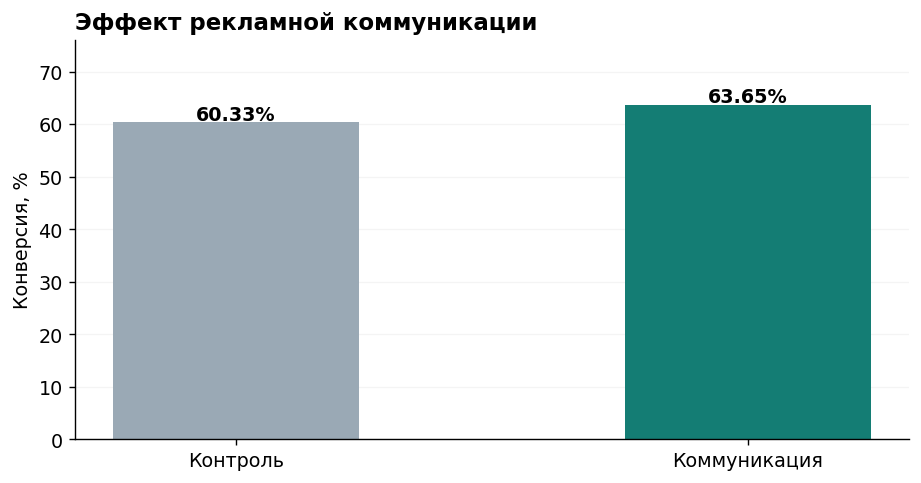

In [19]:
fig, ax = plt.subplots(figsize=(7.5, 4))
vals = [100 * p0, 100 * p1]
bars = ax.bar(['Контроль', 'Коммуникация'], vals,
              color=[GRAY, GREEN], width=0.48)
for bar, val in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.5,
            f'{val:.2f}%', ha='center', fontweight='bold')
ax.set_ylim(0, 76)
ax.set_ylabel('Конверсия, %')
ax.set_title('Эффект рекламной коммуникации', loc='left', weight='bold')
ax.grid(axis='y', alpha=0.13)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

Коммуникация повысила конверсию на **3,32 п. п.** (95% ДИ: **2,90–3,75 п. п.**). Разница статистически значима. Это примерно 33 дополнительных покупателя на 1 000 контактов при переносимости эффекта на аналогичную аудиторию.

## 3. Проверки эксперимента

Проверяем соотношение размеров групп (SRM), баланс доступных характеристик и аномальные значения возраста.

In [20]:
chi2, p_srm = chisquare([n0, n1], [len(data) / 2] * 2)

data['age_clean'] = pd.to_numeric(data['age'], errors='coerce')
data.loc[~data['age_clean'].between(18, 100), 'age_clean'] = np.nan

data['age_group'] = pd.cut(
    data['age_clean'], bins=[17, 29, 44, 59, 74, 100],
    labels=['18–29', '30–44', '45–59', '60–74', '75–100']
).astype('object').fillna('Unknown')
data['gender_group'] = data['gender'].fillna('U')

print(f'SRM p-value: {p_srm:.3f}')
print('Неизвестный/аномальный возраст:', data['age_clean'].isna().sum())
print('Средний возраст (A/B):')
display(data.groupby('treatment_flg')['age_clean'].mean().round(2))
print('Пол, % по группам:')
display((pd.crosstab(data.treatment_flg, data.gender_group,
                     normalize='index') * 100).round(2))

SRM p-value: 0.863
Неизвестный/аномальный возраст: 3236
Средний возраст (A/B):


,age_clean
treatment_flg,
0,46.730
1,46.840


Пол, % по группам:


gender_group,F,M,U
treatment_flg,,,
0,36.760,16.780,46.460
1,36.920,16.730,46.350


SRM не выявил отклонения от распределения 50/50 (**p = 0,863**). Возраст и пол распределены между группами близко. Некорректные значения возраста исключены из числового анализа, но сами клиенты оставлены в выборке.

## 4. История покупок и сегменты

По [официальному описанию данных RetailHero](https://ods.ai/competitions/x5-retailhero-uplift-modeling/data), `purchases.csv` содержит покупки **до** рекламной коммуникации, а `target` в `uplift_train.csv` отражает покупку после неё. Точной даты отправки SMS в таблицах эксперимента нет. Не следует принимать дату чеков за дату воздействия.

В базовом запуске история не подгружается; при `BUILD_RFM = True` ячейка выше загружает большой файл покупок (~609 МБ) и рассчитывает признаки из доэкспериментальной истории: количество чеков, сумму трат, средний чек, давность последней покупки (относительно конца **исторического файла**, а не даты SMS), длину истории и активность за 30/90 дней.

Данные агрегируются в `final_stats.csv` по `client_id`. Дополнительный файл используется только как предэкспериментальный набор признаков. **Результаты uplift с расширенными признаками нельзя выдавать за проверенные, пока ноутбук не выполнен с этим файлом и не проведена независимая валидация.**

In [21]:
# OPTIONAL: history features for the extended model; full purchases.csv.gz is ~609 MB.
# Change to True only when ready to download and process the entire transaction file.
BUILD_RFM = True

if BUILD_RFM:
    import subprocess
    import sys
    from urllib.request import urlretrieve

    print('Скачиваем историю покупок (официальные данные до коммуникации)...')
    purchases_path = hf_hub_download(
        repo_id=REPO, filename='data/purchases.csv.gz', repo_type='dataset'
    )
    script_path = Path('build_rfm_features.py')
    script_url = ('https://raw.githubusercontent.com/venfun77/retailhero-ab-uplift/'
                  'd243fbd4adcbf9e3ca33d81620d5387197ff6b87/scripts/build_rfm_features.py')
    urlretrieve(script_url, script_path)
    subprocess.run([sys.executable, '-m', 'pip', '-q', 'install', 'duckdb'], check=True)
    subprocess.run([
        sys.executable, str(script_path), '--input', str(purchases_path),
        '--output', str(DATA_DIR / 'final_stats.csv')
    ], check=True)
    print('RFM-признаки готовы:', DATA_DIR / 'final_stats.csv')
else:
    print('Базовый запуск: история покупок не загружается (BUILD_RFM = True).')

Скачиваем историю покупок (официальные данные до коммуникации)...


data/purchases.csv.gz: reconstructing file:   0%|          |  0.00B /  609MB            

data/purchases.csv.gz: downloading bytes:           |  0.00B            

RFM-признаки готовы: data/final_stats.csv


In [22]:
feature_file = next((p for p in [Path('final_stats.csv'), DATA_DIR / 'final_stats.csv']
                     if p.exists()), None)
has_history = feature_file is not None

extra_columns = ['mean_check', 'recency_days', 'active_span_days',
                 'checks_30d', 'checks_90d', 'spending_90d']
rename = {'count': 'pre_checks', 'sum': 'pre_spending'}
rename.update({col: 'pre_' + col for col in extra_columns})

if has_history:
    history = pd.read_csv(feature_file, dtype={'client_id': 'string'})
    required = {'client_id', 'count', 'sum'}
    if not required.issubset(history.columns):
        raise ValueError(f'Feature file must contain {sorted(required)}')
    available = ['client_id', 'count', 'sum'] + [
        col for col in extra_columns if col in history.columns
    ]
    history = history[available].rename(columns=rename)
    data = data.merge(history, on='client_id', how='left', validate='one_to_one')
    print('История покупок подключена:', feature_file)
    print('Доступные поведенческие признаки:', available[1:])
    display(data.groupby('treatment_flg')[['pre_checks', 'pre_spending']].mean().round(2))
else:
    print('История покупок не найдена — доступны демографические признаки.')

История покупок подключена: data/final_stats.csv
Доступные поведенческие признаки: ['count', 'sum', 'mean_check', 'recency_days', 'active_span_days', 'checks_30d', 'checks_90d', 'spending_90d']


,pre_checks,pre_spending
treatment_flg,,
0,20.060,88417.760
1,20.190,89088.360


In [23]:
segments = ['age_group', 'gender_group']

if has_history:
    for col, name in [('pre_checks', 'checks_group'),
                      ('pre_spending', 'spending_group')]:
        quartile = pd.qcut(data[col], 4, labels=False, duplicates='drop')
        data[name] = quartile.map(
            lambda x: f'Q{int(x) + 1}' if pd.notna(x) else 'Unknown'
        )
        segments.append(name)


def compare_segments(column):
    rows = []
    for name, group in data.groupby(column):
        a = group.loc[group.treatment_flg.eq(0), 'target']
        b = group.loc[group.treatment_flg.eq(1), 'target']
        if len(a) < 30 or len(b) < 30:
            continue
        pa, pb = a.mean(), b.mean()
        d = pb - pa
        err = np.sqrt(pa * (1 - pa) / len(a) + pb * (1 - pb) / len(b))
        _, p = proportions_ztest([b.sum(), a.sum()], [len(b), len(a)])
        rows.append([column, str(name), len(a), len(b),
                     100 * pa, 100 * pb, 100 * d,
                     100 * (d - 1.96 * err), 100 * (d + 1.96 * err), p])
    return pd.DataFrame(rows, columns=[
        'dimension', 'segment', 'n_control', 'n_treatment',
        'control_%', 'treatment_%', 'uplift_pp', 'ci_low', 'ci_high', 'p_value'
    ])

segment_results = pd.concat([compare_segments(s) for s in segments], ignore_index=True)
segment_results['p_fdr'] = multipletests(segment_results.p_value, method='fdr_bh')[1]
display(segment_results.round(3))

,dimension,segment,n_control,n_treatment,control_%,treatment_%,uplift_pp,ci_low,ci_high,p_value,p_fdr
0,age_group,18–29,14587,14636,58.100,59.415,1.315,0.187,2.444,0.022,0.024
1,age_group,30–44,32753,32200,59.216,61.795,2.579,1.827,3.331,0.000,0.000
2,age_group,45–59,26787,27020,60.290,63.756,3.466,2.646,4.286,0.000,0.000
3,age_group,60–74,21058,21132,63.211,68.285,5.074,4.170,5.978,0.000,0.000
4,age_group,75–100,3296,3334,65.868,72.765,6.898,4.683,9.112,0.000,0.000
5,age_group,Unknown,1577,1659,54.597,57.987,3.389,-0.028,6.807,0.052,0.052
6,gender_group,F,36785,36911,62.044,66.070,4.025,3.333,4.718,0.000,0.000
7,gender_group,M,16786,16725,60.682,63.611,2.930,1.892,3.968,0.000,0.000
8,gender_group,U,46487,46345,58.842,61.739,2.897,2.268,3.526,0.000,0.000
9,checks_group,Q1,26711,26604,32.429,36.840,4.412,3.605,5.219,0.000,0.000


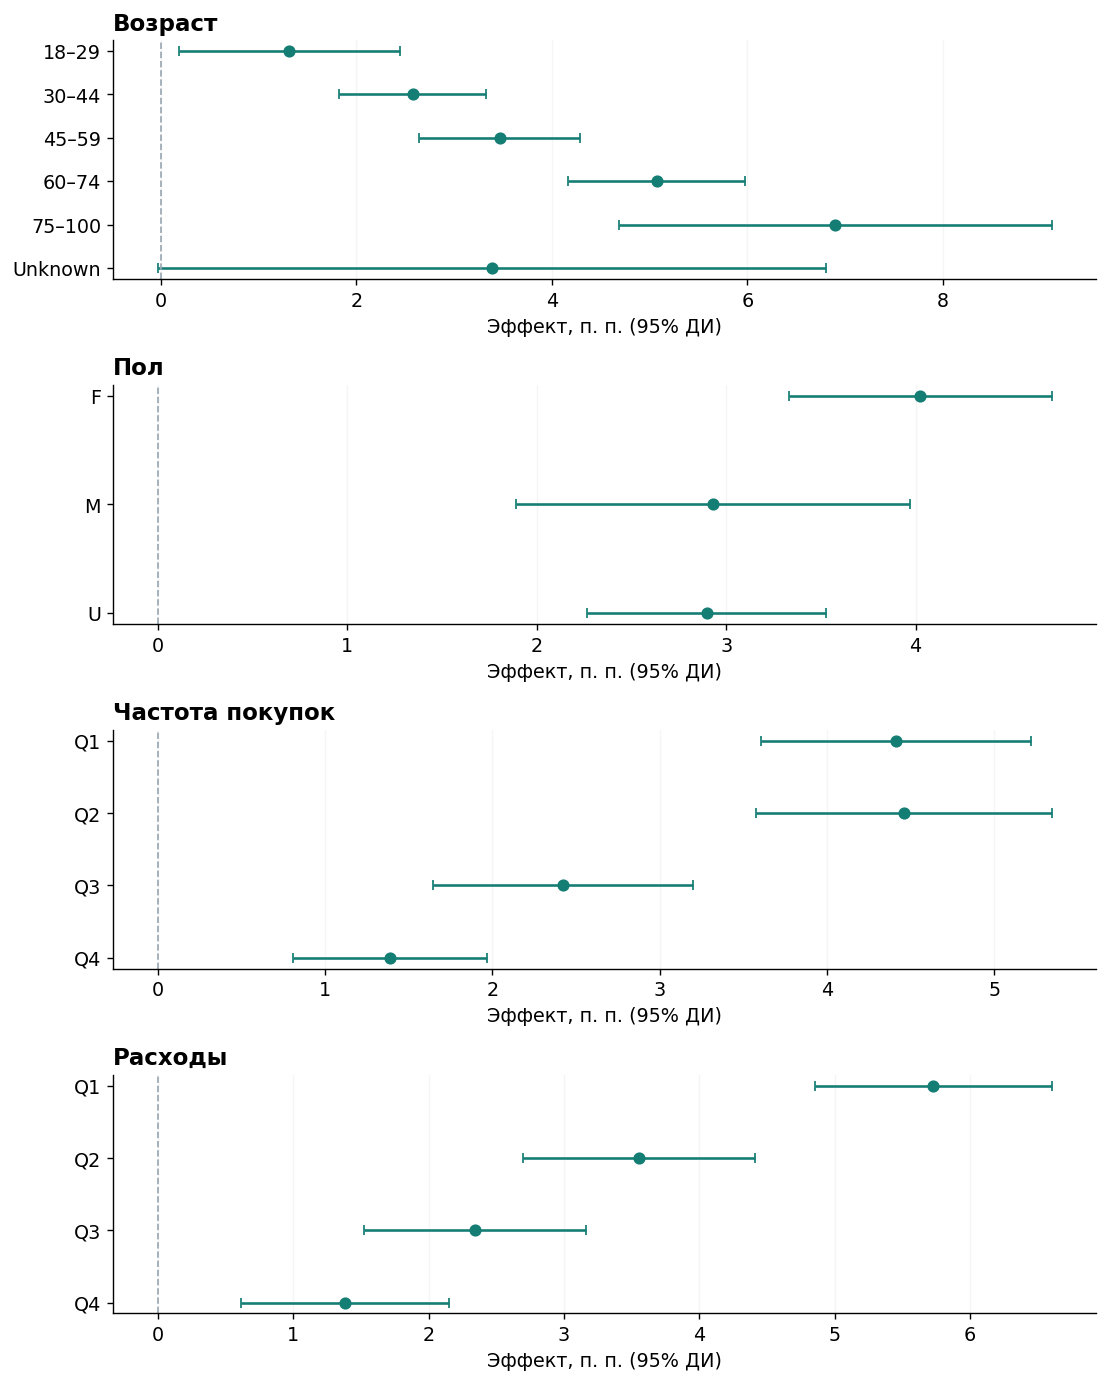

In [24]:
labels = {
    'age_group': 'Возраст', 'gender_group': 'Пол',
    'checks_group': 'Частота покупок', 'spending_group': 'Расходы'
}
fig, axes = plt.subplots(len(segments), 1,
                         figsize=(9, len(segments) * 2.8), squeeze=False)

for ax, col in zip(axes.ravel(), segments):
    part = segment_results.loc[segment_results.dimension.eq(col)].copy()
    if col == 'age_group':
        order = ['18–29', '30–44', '45–59', '60–74', '75–100', 'Unknown']
        part['rank'] = part.segment.map({x: i for i, x in enumerate(order)})
        part = part.sort_values('rank')
    else:
        part = part.sort_values('segment')

    x = part.uplift_pp.to_numpy()
    errors = [x - part.ci_low.to_numpy(), part.ci_high.to_numpy() - x]
    y = np.arange(len(part))
    ax.errorbar(x, y, xerr=errors, fmt='o', color=GREEN,
                capsize=3, markersize=6)
    ax.axvline(0, linestyle='--', color=GRAY, linewidth=1)
    ax.set_yticks(y, part.segment)
    ax.invert_yaxis()
    ax.set_xlabel('Эффект, п. п. (95% ДИ)')
    ax.set_title(labels[col], loc='left', weight='bold')
    ax.grid(axis='x', alpha=0.12)

plt.tight_layout()
plt.show()

По результатам сегментации больший отклик наблюдается у некоторых старших возрастных групп. Сегменты по расходам доступны **только при загрузке исторических покупок**. Статистически значимые эффекты внутри отдельных групп не доказывают автоматически различие эффектов между группами; ниже приведены тесты взаимодействий.

In [25]:
interaction_rows = []
for col in segments:
    model = smf.ols(f'target ~ treatment_flg * C({col})', data=data).fit(cov_type='HC3')
    terms = [k for k in model.params.index if k.startswith('treatment_flg:C(')]
    if not terms:
        continue
    r = np.zeros((len(terms), len(model.params)))
    for i, term in enumerate(terms):
        r[i, model.params.index.get_loc(term)] = 1
    test = model.wald_test(r, scalar=True)
    interaction_rows.append([col, float(test.statistic), float(test.pvalue)])

interaction_results = pd.DataFrame(
    interaction_rows, columns=['segment', 'wald_stat', 'p_value']
)
interaction_results['p_fdr'] = multipletests(
    interaction_results.p_value, method='fdr_bh'
)[1]
display(interaction_results.round(4))

,segment,wald_stat,p_value,p_fdr
0,age_group,40.408,0.000,0.000
1,gender_group,6.267,0.044,0.044
2,checks_group,52.337,0.000,0.000
3,spending_group,58.407,0.000,0.000


## 5. Uplift-модель

Для персонализации коммуникации используем **T-learner** — две модели градиентного бустинга, обученные отдельно на контроле и эксперименте. Разница их прогнозов даёт оценку дополнительной вероятности покупки при коммуникации.

Качество проверяем на отложенных **30% клиентов**, которые не использовались при обучении.

In [26]:
ml = data.copy()
ml['age_unknown'] = ml.age_clean.isna().astype(int)
ml['age_value'] = ml.age_clean.fillna(ml.age_clean.median())

x_cols = ['age_value', 'age_unknown']
gender = pd.get_dummies(ml.gender_group, prefix='gender')
ml = pd.concat([ml, gender], axis=1)
x_cols += gender.columns.tolist()

if has_history:
    behavior_features = ['pre_checks', 'pre_spending'] + [
        'pre_' + name for name in extra_columns if 'pre_' + name in ml.columns
    ]
    for col in behavior_features:
        ml[f'{col}_missing'] = ml[col].isna().astype(int)
        ml[col] = pd.to_numeric(ml[col], errors='coerce')
        ml[col] = ml[col].fillna(ml[col].median())
        x_cols += [col, f'{col}_missing']

X = ml[x_cols].astype(float)
y = ml.target.astype(int)
t = ml.treatment_flg.astype(int)
strata = t.astype(str) + '_' + y.astype(str)

idx_train, idx_test = train_test_split(
    ml.index, test_size=0.30, stratify=strata, random_state=42
)

models = {}
for treatment in [0, 1]:
    train_subset = idx_train[t.loc[idx_train].eq(treatment).to_numpy()]
    clf = HistGradientBoostingClassifier(
        learning_rate=0.05, max_depth=4, max_iter=250,
        min_samples_leaf=80, random_state=42
    )
    clf.fit(X.loc[train_subset], y.loc[train_subset])
    models[treatment] = clf

pred0 = models[0].predict_proba(X.loc[idx_test])[:, 1]
pred1 = models[1].predict_proba(X.loc[idx_test])[:, 1]

holdout = ml.loc[idx_test, ['treatment_flg', 'target']].copy()
holdout['uplift_score'] = pred1 - pred0
holdout = holdout.sort_values('uplift_score', ascending=False).reset_index(drop=True)

print('Train:', len(idx_train), '| Holdout:', len(idx_test))
print('Признаки:', ', '.join(x_cols))

Train: 140027 | Holdout: 60012
Признаки: age_value, age_unknown, gender_F, gender_M, gender_U, pre_checks, pre_checks_missing, pre_spending, pre_spending_missing, pre_mean_check, pre_mean_check_missing, pre_recency_days, pre_recency_days_missing, pre_active_span_days, pre_active_span_days_missing, pre_checks_30d, pre_checks_30d_missing, pre_checks_90d, pre_checks_90d_missing, pre_spending_90d, pre_spending_90d_missing


In [27]:
def observed_uplift(frame):
    rates = frame.groupby('treatment_flg').target.mean()
    return rates.loc[1] - rates.loc[0]

baseline = observed_uplift(holdout)
rows = []
for share in [0.1, 0.2, 0.3, 0.5, 1.0]:
    top = holdout.head(max(1, int(len(holdout) * share)))
    rows.append([share, len(top), 100 * observed_uplift(top)])

topk = pd.DataFrame(rows, columns=['share', 'clients', 'uplift_pp'])

holdout['decile'] = pd.qcut(
    holdout.uplift_score.rank(method='first', ascending=False),
    10, labels=[f'D{i}' for i in range(1, 11)]
)
decile_rows = []
for name, group in holdout.groupby('decile', observed=True):
    decile_rows.append([str(name), len(group),
                        group.uplift_score.mean(), 100 * observed_uplift(group)])
deciles = pd.DataFrame(decile_rows, columns=['decile', 'clients', 'score', 'uplift_pp'])

print(f'Средний uplift на holdout: {100 * baseline:.2f} п. п.')
display(topk.round(3))
display(deciles.round(3))

Средний uplift на holdout: 3.32 п. п.


,share,clients,uplift_pp
0,0.100,6001,6.794
1,0.200,12002,6.067
2,0.300,18003,4.785
3,0.500,30006,3.937
4,1.000,60012,3.321


,decile,clients,score,uplift_pp
0,D1,6002,0.112,6.808
1,D2,6001,0.070,5.352
2,D3,6001,0.053,2.270
3,D4,6001,0.041,2.124
4,D5,6001,0.031,3.063
5,D6,6001,0.022,3.003
6,D7,6001,0.014,2.616
7,D8,6001,0.006,1.379
8,D9,6001,-0.005,1.331
9,D10,6002,-0.028,4.216


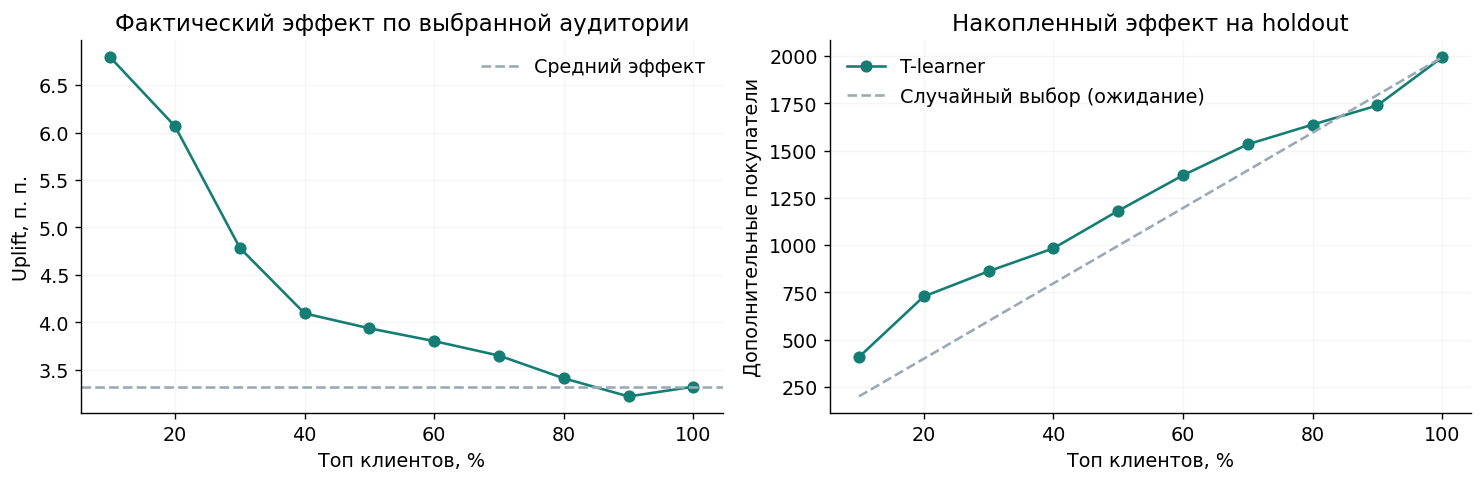

In [28]:
curve = []
for share in np.linspace(0.1, 1.0, 10):
    top = holdout.head(max(1, int(len(holdout) * share)))
    curve.append([share, 100 * observed_uplift(top),
                  len(top) * observed_uplift(top)])
curve = pd.DataFrame(curve, columns=['share', 'uplift_pp', 'extra_buyers'])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(curve.share * 100, curve.uplift_pp, '-o', color=GREEN)
ax[0].axhline(100 * baseline, linestyle='--', color=GRAY, label='Средний эффект')
ax[0].set(xlabel='Топ клиентов, %', ylabel='Uplift, п. п.',
          title='Фактический эффект по выбранной аудитории')
ax[0].legend(frameon=False)

ax[1].plot(curve.share * 100, curve.extra_buyers, '-o', color=GREEN,
           label='T-learner')
ax[1].plot(curve.share * 100, len(holdout) * curve.share * baseline,
           '--', color=GRAY, label='Случайный выбор (ожидание)')
ax[1].set(xlabel='Топ клиентов, %', ylabel='Дополнительные покупатели',
          title='Накопленный эффект на holdout')
ax[1].legend(frameon=False)
for a in ax:
    a.grid(alpha=0.12)
plt.tight_layout()
plt.show()

## 6. Выводы и ограничения

- Историческая SMS-коммуникация ассоциирована с эффектом **+3,32 п. п.** к конверсии (95% ДИ **[+2,90; +3,75]**); этот эффект относится к исходному эксперименту, который автор проекта не запускал.
- **Базовая T-learner** (возраст и пол) на holdout: uplift топ-10% **+4,922 п. п.**, оценка преимущества над случайным выбором **+1,591 п. п.**, 95% bootstrap ДИ **[−0,756; +3,898]** — включает ноль.
- **Расширенная RFM-модель**, запущенная в Colab с `BUILD_RFM = True` 30.10.2026: точечное преимущество **+3,483 п. п.**, 95% bootstrap ДИ **[+1,129; +5,922]**; сценарный эффект около **+209 дополнительных покупок при 6000 контактах** (95% ДИ **[+68; +355]**).
- Bootstrap по фиксированной расширенной модели на историческом holdout поддерживает положительный эффект, **но не корректирует повторное использование того же holdout для выбора модели**. Нужна независимая оценка и проспективный A/B-тест двух политик рассылки.
- Финансовые результаты носят условный характер: нет фактической стоимости SMS, скидок и маржинальности.

**Следующий шаг:** см. [дизайн эксперимента](../docs/next_ab_experiment.md). Для воспроизведения расширенных результатов нужно установить `BUILD_RFM = True` (по умолчанию отключено из-за размера исходных данных).

## 7. Бизнес-сценарий при фиксированном бюджете SMS

Ниже — расчёт возможного эффекта выбора **6 000 контактов**. Сравниваем случайный выбор с топ-10% по uplift-модели при одинаковом количестве SMS. Все предположения (маржа, цена контакта) обозначены как условные. Выводы по фактическому финансовому ROI без данных о расходах и марже делать нельзя. Разница в uplift — **точечная оценка**, которая может быть неустойчивой; новый A/B-тест политик описан отдельно.

In [29]:
# Бизнес-интерпретация — только условная оценка на историческом holdout
# Используем уже рассчитанные holdout, baseline и topk; данные новых кампаний не моделируются.
top10_uplift = topk.loc[np.isclose(topk['share'], 0.1), 'uplift_pp'].iloc[0] / 100
contacts = 6000
scenario_margin = 200  # ₽; иллюстративное предположение, не реальная маржа X5
scenario_sms_cost = 3  # ₽; иллюстративное предположение, не реальная цена SMS
random_extra = contacts * baseline
model_extra = contacts * top10_uplift
improvement = (model_extra / random_extra - 1) if random_extra > 0 else np.nan
cost_reduction = (1 - random_extra / model_extra) if model_extra > 0 else np.nan
incremental_margin = (model_extra - random_extra) * scenario_margin
print(f'Для {contacts:,} контактов: случайный выбор ≈{random_extra:.0f}, модель ≈{model_extra:.0f} дополнительных покупок')
print(f'Точечная оценка улучшения: {100 * improvement:+.1f}%; сокращение стоимости одной дополнительной покупки: {100 * cost_reduction:.1f}%')
print(f'Сценарий при марже {scenario_margin} ₽: преимущество ~{incremental_margin:,.0f} ₽ до затрат на модель')
print(f'Бюджет SMS при цене {scenario_sms_cost} ₽: {contacts * scenario_sms_cost:,.0f} ₽ в обеих стратегиях')
print('Это не новый A/B-тест; приведены оценки на старой отложенной выборке.')

Для 6,000 контактов: случайный выбор ≈199, модель ≈408 дополнительных покупок
Точечная оценка улучшения: +104.5%; сокращение стоимости одной дополнительной покупки: 51.1%
Сценарий при марже 200 ₽: преимущество ~41,666 ₽ до затрат на модель
Бюджет SMS при цене 3 ₽: 18,000 ₽ в обеих стратегиях
Это не новый A/B-тест; приведены оценки на старой отложенной выборке.


## 8. Проверка статистической неопределённости преимущества таргетинга

Сравниваем uplift в топ-10% и ожидаемый uplift случайного выбора **на фиксированной holdout-выборке**. Для этого разница между эффектом в топ-10% и взвешенным средним эффектом в топ-10% и остальных 90% оценивается при помощи стратифицированного bootstrap по группам (топ/остальные × Treatment/Control).

**Результаты Colab, 30.10.2026:**
- Базовые признаки (возраст и пол): точечное преимущество **+1,591 п. п.**, 95% ДИ **[−0,756; +3,898] п. п.**
- Расширенные RFM-признаки: точечное преимущество **+3,483 п. п.**, 95% ДИ **[+1,129; +5,922] п. п.**

**Статистическая оговорка:** здесь результаты показаны для зафиксированных скорингов. CI **не учитывает** изменение модели при повторном обучении, перенос на новую аудиторию и тот факт, что после анализа базовой модели на этом holdout мы снова использовали ту же выборку для расширенной версии. Для независимой проверки новой политики нужен отдельный эксперимент.

In [30]:
# Устойчивость результата: 95% ДИ эффекта uplift-таргетинга против случайного
# Здесь нет нового A/B-теста — bootstrap выполняется на историческом holdout.
uncertainty = holdout.copy()
top_n = max(1, int(len(uncertainty) * 0.10))
uncertainty['is_top10'] = False
uncertainty.loc[uncertainty.index[:top_n], 'is_top10'] = True
top_share = top_n / len(uncertainty)

stats = uncertainty.groupby(['is_top10', 'treatment_flg']).target.agg(['size', 'sum'])
assert len(stats) == 4 and (stats['size'] > 0).all()

rng = np.random.default_rng(42)
n_boot = 3000
rates = {}
for is_top in [False, True]:
    for treatment in [0, 1]:
        n = int(stats.loc[(is_top, treatment), 'size'])
        successes = int(stats.loc[(is_top, treatment), 'sum'])
        rates[(is_top, treatment)] = rng.binomial(n, successes / n, size=n_boot) / n

tau_top = rates[(True, 1)] - rates[(True, 0)]
tau_other = rates[(False, 1)] - rates[(False, 0)]
tau_random = top_share * tau_top + (1 - top_share) * tau_other
gain_per_contact = tau_top - tau_random

gain_point = observed_uplift(uncertainty.loc[uncertainty.is_top10]) - (
    top_share * observed_uplift(uncertainty.loc[uncertainty.is_top10]) +
    (1 - top_share) * observed_uplift(uncertainty.loc[~uncertainty.is_top10])
)
low, high = np.quantile(gain_per_contact, [0.025, 0.975])
print(f'Превышение uplift над случайной политикой: {100 * gain_point:+.3f} п. п.')
print(f'Bootstrap 95% ДИ: [{100 * low:+.3f}; {100 * high:+.3f}] п. п.')
print(f'При 6000 контактах: оценка {6000 * gain_point:+.0f}, 95% ДИ [{6000 * low:+.0f}; {6000 * high:+.0f}] дополнительных покупок')
if low <= 0 <= high:
    print('Вывод: 95% ДИ включает ноль — статистически убедительного преимущества модели пока нет.')
elif low > 0:
    print('Вывод: интервал выше нуля для фиксированной исторической holdout-модели; нужна независимая проверка новой политики.')
else:
    print('Вывод: интервал ниже нуля на исторической выборке — модель уступает случайной политике.')


Превышение uplift над случайной политикой: +3.483 п. п.
Bootstrap 95% ДИ: [+1.129; +5.922] п. п.
При 6000 контактах: оценка +209, 95% ДИ [+68; +355] дополнительных покупок
Вывод: интервал выше нуля для фиксированной исторической holdout-модели; нужна независимая проверка новой политики.


In [31]:
out = Path('outputs')
out.mkdir(exist_ok=True)
summary.to_csv(out / 'ab_results.csv')
segment_results.to_csv(out / 'segments.csv', index=False)
interaction_results.to_csv(out / 'interactions.csv', index=False)
topk.to_csv(out / 'uplift_topk.csv', index=False)
deciles.to_csv(out / 'uplift_deciles.csv', index=False)
print('Результаты сохранены в outputs/')

Результаты сохранены в outputs/


---

**Данные:** [ODS RetailHero](https://ods.ai/competitions/x5-retailhero-uplift-modeling/data) · [Hugging Face](https://huggingface.co/datasets/pytorch-lifestream/retailhero-uplift/tree/main/data)

**Дизайн следующего эксперимента:** [docs/next_ab_experiment.md](../docs/next_ab_experiment.md)